# Class-weighted NN-duel forecasting on non-overlapping histories

Run **14_prepare_nonoverlap_nn_duel_skill_forecasting.ipynb** first, then this
notebook. It reuses that exact verified dataset and the architecture from notebook
15: **width 96, two Transformer layers, six attention heads and dropout 0.25**.
Inputs remain 51 past frames with 87 features; outputs are opponent catalogue-skill
distributions at +1/+2/+5 seconds. Training raw input histories are disjoint across
both aircraft views of each flight. The same dense test/validation windows are used.

Notebook 15's cross-entropy balances horizons, but every labelled example within a
horizon has equal weight. Common skills therefore dominate the training signal.
This notebook applies **capped inverse-square-root class weights**, separately for
each horizon, using only the **retained training targets after non-overlap sampling**.
It never uses test or validation counts to construct weights or resamples windows.
All catalogue outputs remain present, including classes absent from training.

**Run All trains three seeds (42, 43, 44), up to 100 epochs each**, preserving L1
regularisation, early stopping from epoch one, and overtraining shutdown. Checkpoint
selection, stopping and ordinary reporting use **unweighted evaluation NLL**, matching
notebook 15. Per-class recall/F1, supported macro-F1, accuracy and calibration should
be compared together: class weighting can improve rare-class recall while reducing
common-class accuracy or probability calibration. It cannot learn positive examples
of a skill absent from the retained training data.

The training criterion and fitted weights are recorded separately from raw NLL.
Each run saves `class_weights.json` and `class_weights.csv`, also logged to MLflow.
The dataset receipt comes from `artifacts/nn_duel_nonoverlap_forecasting/`, while new
runs and tracking use `artifacts/nn_duel_balanced_forecasting/`. Set
`BVR_NN_NONOVERLAP_DATA` to override the dataset, or `BVR_NN_BALANCED_MLFLOW=0` to
turn tracking off. Use fresh runs for the new objective; resume requires unchanged
source, data and configuration. Notebook 15 need not be run first.

Install `.[ml]` and an IPython/Jupyter kernel. CUDA uses BF16 when supported; CPU
uses FP32. Streaming avoids caching the full approximately 13.7 GiB frame array on
a 16 GiB GPU. Every executable cell is timed; GPU work is synchronized.


In [1]:
%%time
from pathlib import Path
import os
import sys

root_override = os.environ.get("BVR_NN_ROOT")
candidates = ([Path(root_override).expanduser()] if root_override else
              [Path.cwd(), *Path.cwd().parents])
ROOT = next((p.resolve() for p in candidates
             if (p / "bvr_behavior_prediction/nn_duel_skill_forecasting.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Set BVR_NN_ROOT to the full Trajectory_Classification checkout path.")
sys.path.insert(0, str(ROOT))
from bvr_behavior_prediction.notebook_runtime import require_pyarrow
require_pyarrow()  # Report the kernel environment and native-library repair steps.
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from bvr_behavior_prediction import nn_duel_skill_forecasting as duel_data
from bvr_behavior_prediction.paired_skill_forecasting import (
    HORIZONS, HISTORY_STEPS, RAW_HISTORY_STEPS, SPLITS, read_json, write_json, sha256,
)
DATA_ROOT = ROOT / "artifacts/nn_duel_nonoverlap_forecasting"
EXPERIMENT_ROOT = ROOT / "artifacts/nn_duel_balanced_forecasting"
EXPERIMENT_ROOT.mkdir(parents=True, exist_ok=True)

import torch
from bvr_behavior_prediction.paired_skill_forecasting import (
    DEFAULT_TRAINING, train_model, final_evaluation, metric_tables, resolve_precision,
    fit_class_weighting, class_weight_table,
)
from bvr_behavior_prediction.paired_skill_tracking import log_run_artifacts

DATA_OVERRIDE = os.environ.get("BVR_NN_NONOVERLAP_DATA")
if not DATA_OVERRIDE and not (DATA_ROOT / "latest_dataset.json").exists():
    raise FileNotFoundError("Run notebook 14 first, or set BVR_NN_NONOVERLAP_DATA to its dataset directory.")
receipt = None if DATA_OVERRIDE else read_json(DATA_ROOT / "latest_dataset.json")
DATA = Path(DATA_OVERRIDE or receipt["directory"]).expanduser().resolve()
if receipt and sha256(DATA / "manifest.json") != receipt["manifest_sha256"]:
    raise ValueError("The prepared dataset changed since notebook 14 completed.")
data = duel_data.NonoverlappingNNDuelData(DATA)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TRAINING_SEEDS = [42, 43, 44]  # One independently fitted three-horizon NN per seed.
TRAIN_MODEL = True
RESUME = False
EXISTING_RUNS = {}  # For resume/report-only: {42: r"C:\...\runs\nn-duel-balanced-s42_...", ...}.
if not TRAINING_SEEDS or len(set(TRAINING_SEEDS)) != len(TRAINING_SEEDS):
    raise ValueError("Choose at least one distinct training seed.")
if (RESUME or not TRAIN_MODEL) and set(EXISTING_RUNS) != set(TRAINING_SEEDS):
    raise ValueError("Set EXISTING_RUNS for every selected seed when resuming or reporting.")
RUN_STAMP = pd.Timestamp.now(tz="UTC").strftime("%Y%m%dT%H%M%S%fZ")
RUNS = {seed: Path(EXISTING_RUNS[seed]).expanduser().resolve() if seed in EXISTING_RUNS
        else EXPERIMENT_ROOT / "runs" / f"nn-duel-balanced-s{seed}_{RUN_STAMP}"
        for seed in TRAINING_SEEDS}
CONFIG = dict(DEFAULT_TRAINING)
CONFIG.update(width=96, dropout=0.25, epochs=100, early_stopping=True, early_stopping_min_epochs=0,
              early_stopping_patience=10, l1_lambda=1e-6,
              class_weighting="sqrt_inverse", max_class_weight_ratio=5.0,
              overtraining_shutdown=True, overtraining_patience=3,
              overtraining_relative_increase=0.05, overtraining_min_gap=0.1,
              precision="bf16", batch_size=512,
              evaluation_batch_size=1024, data_backend="prefetch" if DEVICE == "cuda" else "direct",
              num_workers=2, cpu_threads=4, compile_model=False)
MLFLOW_ENABLED = os.environ.get("BVR_NN_BALANCED_MLFLOW", "1") == "1"
MLFLOW_TRACKING_URI = os.environ.get("MLFLOW_TRACKING_URI",
    f"sqlite:///{(EXPERIMENT_ROOT / 'mlflow.db').as_posix()}")
TRACKING = {"enabled": MLFLOW_ENABLED, "tracking_uri": MLFLOW_TRACKING_URI,
            "experiment": "nn-duel-balanced-skill-forecasting", "log_per_class": True,
            "log_model": True,
            "artifact_root": (EXPERIMENT_ROOT / "mlflow_artifacts").as_uri()
                             if MLFLOW_TRACKING_URI.startswith("sqlite:") else None}
print("Prepared dataset:", DATA)
print("Model run directories:", {s: str(p) for s, p in RUNS.items()})
display(pd.Series({**CONFIG, "device": DEVICE,
    "effective_precision": resolve_precision(DEVICE, CONFIG["precision"]),
    "input_features": len(data.manifest["features"]), "classes": len(data.classes),
    "history_steps": HISTORY_STEPS, "horizons_s": HORIZONS}))
display(pd.DataFrame(data.manifest["counts"]).T)
if MLFLOW_ENABLED and MLFLOW_TRACKING_URI.startswith("sqlite:"):
    print(f'mlflow ui --backend-store-uri "{MLFLOW_TRACKING_URI}" --host 127.0.0.1 --port 5000')
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    torch.cuda.synchronize()

# This audit reads only labels retained in the training partition.
CLASS_WEIGHTING = fit_class_weighting(data, CONFIG)
CLASS_WEIGHT_AUDIT = class_weight_table(CLASS_WEIGHTING)
with pd.option_context("display.max_rows", None):
    display(CLASS_WEIGHT_AUDIT.pivot(index="skill", columns="horizon_s",
                                    values=["training_support", "weight"]).round(4))
print("Zero-training-support skill/horizon pairs:")
display(CLASS_WEIGHT_AUDIT.loc[CLASS_WEIGHT_AUDIT.training_support.eq(0)])


Prepared dataset: C:\Users\theon\Trajectory_Classification\artifacts\nn_duel_nonoverlap_forecasting\data\eee3474c5493_5b951842316d_0a5d2704_7661ce18
Model run directories: {42: 'C:\\Users\\theon\\Trajectory_Classification\\artifacts\\nn_duel_balanced_forecasting\\runs\\nn-duel-balanced-s42_20261109T145721621078Z', 43: 'C:\\Users\\theon\\Trajectory_Classification\\artifacts\\nn_duel_balanced_forecasting\\runs\\nn-duel-balanced-s43_20261109T145721621078Z', 44: 'C:\\Users\\theon\\Trajectory_Classification\\artifacts\\nn_duel_balanced_forecasting\\runs\\nn-duel-balanced-s44_20261109T145721621078Z'}


epochs                                     100
seed                                        42
batch_size                                 512
evaluation_batch_size                     1024
learning_rate                           0.0003
weight_decay                              0.01
gradient_clip                              1.0
width                                       96
heads                                        6
layers                                       2
dropout                                   0.25
early_stopping                            True
early_stopping_min_epochs                    0
early_stopping_patience                     10
precision                                 bf16
data_backend                          prefetch
num_workers                                  2
prefetch_factor                              2
cpu_threads                                  4
loader_timeout                              60
compile_model                            False
compile_mode 

,groups,episodes,windows,labels_by_horizon
train,4000,8000,137001,"[137001, 136791, 136135]"
test,3000,6000,1224086,"[1224086, 1218086, 1200100]"
validation,3000,6000,1224414,"[1224414, 1218414, 1200422]"


mlflow ui --backend-store-uri "sqlite:///C:/Users/theon/Trajectory_Classification/artifacts/nn_duel_balanced_forecasting/mlflow.db" --host 127.0.0.1 --port 5000
GPU: NVIDIA GeForce RTX 5080 Laptop GPU


training_support                    weight                
horizon_s                          1        2        5       1       2       5
skill                                                                         
abort_support                  173.0    169.0    168.0  3.0238  3.0267  3.0336
accelerate_to_speed              1.0      1.0      0.0  3.0238  3.0267  0.0000
beam_missile_left               34.0     29.0     22.0  3.0238  3.0267  3.0336
beam_missile_right             132.0    130.0    113.0  3.0238  3.0267  3.0336
beam_target_left              5543.0   5524.0   5370.0  1.5949  1.6008  1.6351
beam_target_right             2644.0   2595.0   2436.0  2.3093  2.3356  2.4277
climb_to_altitude                1.0      3.0      2.0  3.0238  3.0267  3.0336
commit                           0.0      1.0      1.0  0.0000  3.0267  3.0336
crank_target_left             2179.0   2099.0   1760.0  2.5438  2.5970  2.8561
crank_target_right            4229.0   4220.0   4253.0  1.8259  1.8315  1.8373
decelerate_to_speed            409.0    402.0    356.0  3.0238  3.0267  3.0336
defensive_reversal              54.0     52.0     45.0  3.0238  3.0267  3.0336
descend_to_altitude            382.0    360.0    319.0  3.0238  3.0267  3.0336
dive_defense                     1.0      0.0      0.0  3.0238  0.0000  0.0000
drag_missile                     5.0      4.0      4.0  3.0238  3.0267  3.0336
extend                       11173.0  11164.0  11176.0  1.1234  1.1261  1.1334
lag_pursuit                  21647.0  21660.0  21628.0  0.8071  0.8084  0.8147
last_ditch_break                 5.0      4.0      3.0  3.0238  3.0267  3.0336
launch                         321.0    303.0    278.0  3.0238  3.0267  3.0336
lead_pursuit                  2150.0   2132.0   2080.0  2.5609  2.5768  2.6272
lock_target                      7.0      6.0      5.0  3.0238  3.0267  3.0336
maintain_heading                39.0     39.0     27.0  3.0238  3.0267  3.0336
notch_left                     183.0    177.0    154.0  3.0238  3.0267  3.0336
notch_right                     78.0     75.0     65.0  3.0238  3.0267  3.0336
preemptive_crank                 6.0      4.0      3.0  3.0238  3.0267  3.0336
pursue_target                 6037.0   6046.0   6027.0  1.5282  1.5302  1.5434
recommit                     38551.0  38631.0  39001.0  0.6048  0.6053  0.6067
search                           7.0      5.0      6.0  3.0238  3.0267  3.0336
secondary_shot               11696.0  11690.0  11656.0  1.0980  1.1004  1.1098
short_range_attack             560.0    530.0    476.0  3.0238  3.0267  3.0336
support_missile                116.0    123.0    105.0  3.0238  3.0267  3.0336
turn_cold                    28569.0  28542.0  28538.0  0.7025  0.7043  0.7093
turn_to_heading                 69.0     71.0     58.0  3.0238  3.0267  3.0336

Zero-training-support skill/horizon pairs:


,horizon_s,skill,training_support,training_frequency,weight
7,1,commit,0,0.0,0.0
46,2,dive_defense,0,0.0,0.0
67,5,accelerate_to_speed,0,0.0,0.0
79,5,dive_defense,0,0.0,0.0


CPU times: total: 1min 16s
Wall time: 1min 31s


## Fit independently seeded networks

Let `n[h,c]` be the number of retained training labels for class `c` at horizon
`h`, ignoring missing targets (`-1`), and `n_max[h]` the largest such class count.
For classes seen during training, form

`r[h,c] = min(5, sqrt(n_max[h] / n[h,c]))`

and normalise by the training-frequency weighted mean:

`w[h,c] = r[h,c] / sum_c(training_frequency[h,c] * r[h,c])`.

The rare/common per-example loss ratio is at most 5. For example, an uncapped 16:1
support ratio gives rare examples four times the weight of common examples. The
frequency-weighted mean weight is one for each horizon, keeping the expected loss
scale comparable with unweighted CE and L1. Zero-support classes receive zero
positive-target weight and retain their output logits. Their absence is audited.

For each horizon, average `w[h,y] * (-log p[h,y])` over its valid labels; then average
the represented horizons equally. The denominator is the number of valid labels,
not the minibatch sum of weights: weights remain effective even when a minibatch
contains just one class. Missing labels contribute neither loss nor gradient.
The masked weighted cross-entropy is implemented in FP32 under BF16 training too.

The loss uses independent missing-label masks. Scaling and the split are fixed by notebook 14 for every seed.
The training objective adds `l1_lambda * sum(abs(model_weights))` (default `1e-6`) to
masked class-weighted cross-entropy. This includes trainable matrix/tensor weights and position
embeddings, excluding biases and LayerNorm scales. AdamW weight decay remains 0.01.
Train/test NLL is evaluated without L1, in evaluation mode; checkpoint selection
therefore remains comparable across epochs. History records the L1 contribution,
evaluation-mode weighted training cross-entropy (`train_data_loss`), its sum with
L1 (`train_objective`), and the unweighted test-minus-train NLL gap separately.
Unweighted mean test NLL still selects checkpoints and drives both stopping rules;
the objective is not changed to favour a checkpoint based on weighted test scores.

Early-stopping patience counts from epoch one: ten consecutive epochs without a
new all-time minimum test NLL stop the run (earliest plateau stop: epoch 11).
There is no minimum training duration. A separate overtraining shutdown stops after
three consecutive epochs where all of these hold: test NLL exceeds its best by
more than 5%, test-minus-train NLL exceeds 0.1, and train NLL is below its value at
the best-test checkpoint. A recovery resets this counter. These are configurable
starting thresholds, not tuned guarantees. The shutdown acts independently of
ordinary patience and preserves `best.pt`; counters and the stop reason survive
resume. Set both `early_stopping=False` and `overtraining_shutdown=False` to run
the full epoch budget. `RESUME=True` requires the same source, data and configuration.
Checkpoint input dimensions, feature ordering and dataset digest are stored with weights.


In [2]:
%%time
histories = {}
def epoch_output(row, summary, per_class):
    print(f"Epoch {row['epoch']}: train NLL={row['train_nll']:.5f}, "
          f"test NLL={row['test_nll']:.5f}, "
          f"weighted train CE={row['train_data_loss']:.5f}, "
          f"L1={row['train_l1_penalty']:.5f}, "
          f"gap={row['generalization_gap']:.5f}, "
          f"overtraining streak={row['overtraining_epochs']}, {row['seconds']:.1f}s", flush=True)
    display(summary[["split", "horizon_s", "nll", "accuracy", "macro_f1",
                     "supported_macro_f1", "weighted_f1"]].round(4))
    with pd.option_context("display.max_rows", None):
        display(per_class.pivot(index=["horizon_s", "skill"], columns="split",
                                 values=["class_nll", "f1", "support"]).round(4))

for seed, run in RUNS.items():
    print(f"Training seed {seed}: {run}", flush=True)
    config = {**CONFIG, "seed": seed}
    tracking = {**TRACKING, "run_name": run.name}
    if TRAIN_MODEL:
        histories[seed] = train_model(data, run, config, callback=epoch_output,
                                     device=DEVICE, resume=RESUME, tracking=tracking)
    else:
        histories[seed] = pd.read_csv(run / "history.csv")
    status = read_json(run / "training_status.json")
    if status["status"] not in {"completed", "early_stopped"}:
        raise ValueError(f"Training has not concluded for seed {seed}.")
    if read_json(run / "run.json")["training"] != config:
        raise ValueError(f"Requested configuration differs from saved seed {seed}.")
    display(histories[seed].tail())
if DEVICE == "cuda":
    torch.cuda.synchronize()


Training seed 42: C:\Users\theon\Trajectory_Classification\artifacts\nn_duel_balanced_forecasting\runs\nn-duel-balanced-s42_20261109T145721621078Z


C:\Users\theon\.conda\envs\trajectory-nn-clean\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/11/09 14:57:30 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/09 14:57:30 INFO mlflow.store.db.utils: Updating database tables


MLflow run: 2098c87838774a24b6550a5028422a77 (nn-duel-balanced-skill-forecasting)
Runtime: cuda, bf16, prefetch, batch 512, evaluation batch 1024, frame cache 0.000 GiB
Epoch 1: train NLL=1.54530, test NLL=1.53214, weighted train CE=1.70005, L1=0.01488, gap=-0.01315, overtraining streak=0, 82.4s


,split,horizon_s,nll,accuracy,macro_f1,supported_macro_f1,weighted_f1
0,train,1,1.5510,0.4381,0.1308,0.1349,0.4309
1,train,2,1.5440,0.4417,0.1333,0.1375,0.4334
2,train,5,1.5409,0.4432,0.1233,0.1312,0.4365
3,test,1,1.5350,0.4471,0.1317,0.1317,0.4396
4,test,2,1.5301,0.4494,0.1324,0.1324,0.4415
5,test,5,1.5313,0.4509,0.1225,0.1225,0.4442


class_nll              f1           support  \
split                              test   train    test   train      test   
horizon_s skill                                                             
1         abort_support          4.9562  4.6547  0.0000  0.0000    1488.0   
          accelerate_to_speed    6.7678  6.2802  0.0000  0.0000       2.0   
          beam_missile_left      5.0427  5.0688  0.0000  0.0000     253.0   
          beam_missile_right     3.7416  3.5926  0.0000  0.0000    1073.0   
          beam_target_left       1.5493  1.5741  0.4339  0.4369   49072.0   
          beam_target_right      2.0135  1.9692  0.2345  0.2480   22525.0   
          climb_to_altitude      5.1070  4.9038  0.0000  0.0000      20.0   
          commit                 5.7787     NaN  0.0000  0.0000       2.0   
          crank_target_left      2.0032  1.8681  0.3120  0.3416   17193.0   
          crank_target_right     1.4628  1.4921  0.4515  0.4479   37913.0   
          decelerate_to_speed    2.8436  2.8606  0.0036  0.0000    3324.0   
          defensive_reversal     4.3293  4.2363  0.0000  0.0000     455.0   
          descend_to_altitude    2.8094  2.7602  0.0922  0.0700    3126.0   
          dive_defense           5.9779  4.9341  0.0000  0.0000       9.0   
          drag_missile           5.5184  5.6915  0.0000  0.0000      39.0   
          extend                 1.5341  1.5710  0.4456  0.4247  100323.0   
          lag_pursuit            1.7431  1.7237  0.3046  0.3248  194366.0   
          last_ditch_break       6.8417  8.0960  0.0000  0.0000      17.0   
          launch                 4.1239  4.0281  0.0000  0.0000    2710.0   
          lead_pursuit           2.4184  2.2817  0.1946  0.2241   19044.0   
          lock_target            5.8584  5.8917  0.0000  0.0000      60.0   
          maintain_heading       5.2828  5.1819  0.0000  0.0000     309.0   
          notch_left             3.9988  3.8729  0.0000  0.0000    1479.0   
          notch_right            4.9432  4.9658  0.0000  0.0000     635.0   
          preemptive_crank       5.6712  5.6311  0.0000  0.0000      40.0   
          pursue_target          2.2924  2.3471  0.0780  0.0541   54139.0   
          recommit               1.2968  1.3190  0.5579  0.5430  347921.0   
          search                 5.7707  8.1379  0.0000  0.0000      52.0   
          secondary_shot         1.2307  1.2620  0.5362  0.5242  104198.0   
          short_range_attack     2.4833  2.2969  0.2099  0.2043    4443.0   
          support_missile        4.7419  4.5974  0.0000  0.0000     981.0   
          turn_cold              1.3703  1.3930  0.4916  0.4737  256315.0   
          turn_to_heading        4.3269  4.3042  0.0000  0.0000     560.0   
2         abort_support          4.8921  4.5954  0.0000  0.0000    1477.0   
          accelerate_to_speed    6.9197  6.0653  0.0000  0.0000       2.0   
          beam_missile_left      4.9190  4.8040  0.0000  0.0000     248.0   
          beam_missile_right     3.8676  3.7916  0.0000  0.0000    1015.0   
          beam_target_left       1.5202  1.5468  0.4523  0.4612   48555.0   
          beam_target_right      1.9979  1.9541  0.2402  0.2477   22040.0   
          climb_to_altitude      5.5775  6.3214  0.0000  0.0000      19.0   
          commit                 6.0808  5.9493  0.0000  0.0000       2.0   
          crank_target_left      2.1238  1.9814  0.2785  0.3198   16215.0   
          crank_target_right     1.4783  1.4945  0.4587  0.4568   37773.0   
          decelerate_to_speed    3.1093  3.0943  0.0000  0.0000    3202.0   
          defensive_reversal     4.7773  4.6287  0.0000  0.0000     434.0   
          descend_to_altitude    2.7322  2.6443  0.1043  0.1366    2988.0   
          dive_defense           4.9806     NaN  0.0000  0.0000       9.0   
          drag_missile           6.3950  6.3658  0.0000  0.0000      39.0   
          extend                 1.5209  1.5535  0.4450  0.4288  100121.0   
          lag_pursuit     

Epoch 2: train NLL=1.42839, test NLL=1.43712, weighted train CE=1.57294, L1=0.01495, gap=0.00873, overtraining streak=0, 45.3s


... (258 outputs left out)

class_nll               f1           support  \
split                              test    train    test   train      test   
horizon_s skill                                                              
1         abort_support          3.9585   2.9025  0.0517  0.1833    1488.0   
          accelerate_to_speed   11.7460   8.7815  0.0000  0.0000       2.0   
          beam_missile_left      4.3899   3.8341  0.0000  0.0000     253.0   
          beam_missile_right     2.4635   1.6144  0.2434  0.4060    1073.0   
          beam_target_left       0.9258   0.8269  0.6558  0.6847   49072.0   
          beam_target_right      1.2205   0.9352  0.4911  0.5692   22525.0   
          climb_to_altitude      9.8822  10.1304  0.0000  0.0000      20.0   
          commit                 9.8913      NaN  0.0000  0.0000       2.0   
          crank_target_left      0.9954   0.6374  0.4870  0.5713   17193.0   
          crank_target_right     1.1744   0.9865  0.6210  0.6663   37913.0   
          decelerate_to_speed    1.7173   1.3286  0.2694  0.3810    3324.0   
          defensive_reversal     3.3952   2.5139  0.0198  0.3226     455.0   
          descend_to_altitude    1.1984   0.6707  0.6093  0.7036    3126.0   
          dive_defense          11.5228   6.0142  0.0000  0.0000       9.0   
          drag_missile           7.1127   5.4711  0.0000  0.0000      39.0   
          extend                 1.2840   1.1035  0.4622  0.5214  100323.0   
          lag_pursuit            1.6585   1.4874  0.3315  0.3978  194366.0   
          last_ditch_break      12.4660   3.4761  0.0000  0.3333      17.0   
          launch                 3.1535   2.4884  0.0955  0.1797    2710.0   
          lead_pursuit           2.3100   1.0261  0.2900  0.4467   19044.0   
          lock_target            6.0970   5.9545  0.0000  0.0000      60.0   
          maintain_heading       4.0738   3.2155  0.0216  0.0909     309.0   
          notch_left             2.7244   1.8122  0.2011  0.3516    1479.0   
          notch_right            3.5816   3.0336  0.0078  0.0426     635.0   
          preemptive_crank       8.9495   5.5137  0.0000  0.0000      40.0   
          pursue_target          2.0266   1.4753  0.3103  0.4325   54139.0   
          recommit               1.1419   1.0732  0.5841  0.6060  347921.0   
          search                 7.3487   5.1656  0.0000  0.0000      52.0   
          secondary_shot         0.9666   0.8653  0.5890  0.6274  104198.0   
          short_range_attack     1.7824   1.2500  0.2993  0.4022    4443.0   
          support_missile        4.0203   2.3762  0.0373  0.2717     981.0   
          turn_cold              1.1745   1.0937  0.5048  0.5322  256315.0   
          turn_to_heading        4.1120   3.8927  0.0071  0.0000     560.0   
2         abort_support          4.0585   2.8581  0.0488  0.1810    1477.0   
          accelerate_to_speed   11.6694   9.0898  0.0000  0.0000       2.0   
          beam_missile_left      4.5162   3.7036  0.0000  0.0000     248.0   
          beam_missile_right     2.5895   1.8510  0.2289  0.4083    1015.0   
          beam_target_left       0.9584   0.8533  0.6480  0.6822   48555.0   
          beam_target_right      1.2556   0.9660  0.4796  0.5585   22040.0   
          climb_to_altitude      8.8758   6.3784  0.0000  0.0000      19.0   
          commit                 8.6276   7.5819  0.0000  0.0000       2.0   
          crank_target_left      1.0530   0.6764  0.4624  0.5558   16215.0   
          crank_target_right     1.2419   1.0468  0.6151  0.6610   37773.0   
          decelerate_to_speed    1.7169   1.3131  0.2768  0.3938    3202.0   
          defensive_reversal     3.2435   2.3286  0.0504  0.3191     434.0   
          descend_to_altitude    1.3107   0.6861  0.5880  0.7195    2988.0   
          dive_defense          12.3902      NaN  0.0000  0.0000       9.0   
          drag_missile           7.3672   5.6186  0.0000  0.0000      39.0   
          extend                 1.2734   1.0917  0.

Early stopping after epoch 28: patience; stale epochs=10, consecutive overtraining epochs=0. Best checkpoint: epoch 18.


,epoch,train_nll,test_nll,train_data_loss,train_l1_penalty,train_objective,generalization_gap,overtraining_detected,overtraining_epochs,stop_reason,train_macro_f1,test_macro_f1,improved,epochs_without_improvement,early_stopped,seconds
23,24,1.162722,1.298100,1.173867,0.015982,1.189849,0.135378,False,0,NaN,0.268430,0.210978,False,6,False,20.313847
24,25,1.164856,1.310599,1.173139,0.016021,1.189159,0.145743,False,0,NaN,0.271406,0.207579,False,7,False,21.843179
25,26,1.144407,1.291544,1.158082,0.016058,1.174141,0.147137,False,0,NaN,0.273588,0.210967,False,8,False,20.098378
26,27,1.144598,1.297063,1.147627,0.016101,1.163728,0.152465,False,0,NaN,0.279019,0.215711,False,9,False,20.222364
27,28,1.150331,1.311795,1.157053,0.016139,1.173192,0.161464,False,0,patience,0.288888,0.212710,False,10,True,20.987674


CPU times: total: 40min 6s
Wall time: 31min 26s


## Final evaluation and a training-frequency baseline

All seeds have finished selection before this cell accesses validation. The selected
checkpoint of each seed is evaluated on train, test and validation, with per-class
NLL/F1/support, confusion matrices and forecast probabilities saved in its run folder.
A Laplace-smoothed training-frequency baseline uses training labels only.
The default report displays the **first configured seed**, chosen before seeing scores;
no winner is selected using validation.


In [3]:
%%time
all_metrics = []
for seed, run in RUNS.items():
    best_epoch, summary, scores, results = final_evaluation(
        data, run, DEVICE, tracking={**TRACKING, "run_name": run.name})
    all_metrics.append(summary.assign(seed=seed, selected_epoch=best_epoch))
    display(Markdown(f"**Seed {seed}, test-selected epoch {best_epoch}**"))
    display(summary.round(4))
    del results  # Release full prediction arrays between independently fitted models.
comparison = pd.concat(all_metrics, ignore_index=True)
for run in RUNS.values():
    comparison.to_csv(run / "seed_comparison.csv", index=False)

frequency = np.zeros((3, len(data.classes)), np.float32)
for h in range(len(HORIZONS)):
    labels = data.targets[data.indices["train"], h]
    counts = np.bincount(labels[labels >= 0], minlength=len(data.classes))
    frequency[h] = (counts + 1) / (counts.sum() + len(data.classes))
baseline_rows = []
for split in SPLITS:
    labels = data.targets[data.indices[split]]
    probabilities = np.broadcast_to(frequency, (len(labels), *frequency.shape))
    baseline, _, _ = metric_tables(labels, probabilities, data.classes, split)
    baseline_rows.append(baseline)
baseline_metrics = pd.concat(baseline_rows, ignore_index=True)
for run in RUNS.values():
    baseline_metrics.to_csv(run / "training_frequency_baseline.csv", index=False)
display(baseline_metrics.assign(model="Training frequency").round(4))

REPORT_SEED = TRAINING_SEEDS[0]
RUN = RUNS[REPORT_SEED]
history = histories[REPORT_SEED]
best_epoch = read_json(RUN / "selection.json")["epoch"]
final_metrics = pd.read_csv(RUN / "final_metrics.csv")
final_per_class = pd.read_csv(RUN / "final_per_class.csv")
final_results = {}
for split in SPLITS:
    with np.load(RUN / f"final_{split}.npz") as stored:
        final_results[split] = {key: stored[key] for key in stored.files}
if DEVICE == "cuda":
    torch.cuda.synchronize()


MLflow run: 2098c87838774a24b6550a5028422a77 (nn-duel-balanced-skill-forecasting)


**Seed 42, test-selected epoch 18**

,split,horizon_s,count,nll,accuracy,macro_f1,supported_macro_f1,weighted_f1
0,train,1,137001,1.1847,0.5326,0.2462,0.2539,0.5303
1,train,2,136791,1.1888,0.5314,0.2457,0.2533,0.5291
2,train,5,136135,1.2119,0.5253,0.2398,0.2552,0.5238
3,test,1,1224086,1.2832,0.5029,0.2109,0.2109,0.5014
4,test,2,1218086,1.2889,0.5016,0.2068,0.2068,0.5001
5,test,5,1200100,1.3066,0.4970,0.1977,0.1977,0.4961
6,validation,1,1224414,1.2940,0.4933,0.2158,0.2297,0.4913
7,validation,2,1218414,1.3001,0.4919,0.2140,0.2278,0.4899
8,validation,5,1200422,1.3185,0.4864,0.2033,0.2164,0.4848


MLflow run: 514f9123d3454b81906cd56601c11827 (nn-duel-balanced-skill-forecasting)


**Seed 43, test-selected epoch 20**

,split,horizon_s,count,nll,accuracy,macro_f1,supported_macro_f1,weighted_f1
0,train,1,137001,1.1714,0.5353,0.2655,0.2738,0.5300
1,train,2,136791,1.1777,0.5334,0.2522,0.2601,0.5283
2,train,5,136135,1.2009,0.5271,0.2470,0.2629,0.5229
3,test,1,1224086,1.2772,0.5026,0.2125,0.2125,0.4983
4,test,2,1218086,1.2847,0.5005,0.2093,0.2093,0.4964
5,test,5,1200100,1.3022,0.4956,0.1987,0.1987,0.4922
6,validation,1,1224414,1.2839,0.4957,0.2177,0.2317,0.4905
7,validation,2,1218414,1.2919,0.4935,0.2150,0.2289,0.4885
8,validation,5,1200422,1.3102,0.4880,0.2038,0.2170,0.4837


MLflow run: 75dcea99d7cb44308b1eeb48721364b1 (nn-duel-balanced-skill-forecasting)


**Seed 44, test-selected epoch 18**

,split,horizon_s,count,nll,accuracy,macro_f1,supported_macro_f1,weighted_f1
0,train,1,137001,1.1731,0.5332,0.2484,0.2561,0.5272
1,train,2,136791,1.1788,0.5319,0.2460,0.2537,0.5259
2,train,5,136135,1.2022,0.5251,0.2400,0.2554,0.5197
3,test,1,1224086,1.2707,0.5056,0.2112,0.2112,0.5005
4,test,2,1218086,1.2776,0.5038,0.2077,0.2077,0.4986
5,test,5,1200100,1.2950,0.4993,0.1982,0.1982,0.4946
6,validation,1,1224414,1.2780,0.4943,0.2155,0.2294,0.4884
7,validation,2,1218414,1.2858,0.4929,0.2111,0.2247,0.4869
8,validation,5,1200422,1.3037,0.4863,0.2000,0.2129,0.4809


,split,horizon_s,count,nll,accuracy,macro_f1,supported_macro_f1,weighted_f1,model
0,train,1,137001,2.0901,0.2814,0.0133,0.0137,0.1236,Training frequency
1,train,2,136791,2.0845,0.2824,0.0133,0.0138,0.1244,Training frequency
2,train,5,136135,2.0636,0.2865,0.0135,0.0144,0.1276,Training frequency
3,test,1,1224086,2.0745,0.2842,0.0134,0.0134,0.1258,Training frequency
4,test,2,1218086,2.0687,0.2852,0.0135,0.0135,0.1266,Training frequency
5,test,5,1200100,2.0506,0.2882,0.0136,0.0136,0.1289,Training frequency
6,validation,1,1224414,2.0744,0.2843,0.0134,0.0143,0.1259,Training frequency
7,validation,2,1218414,2.0686,0.2853,0.0135,0.0143,0.1266,Training frequency
8,validation,5,1200422,2.0504,0.2882,0.0136,0.0144,0.1290,Training frequency


CPU times: total: 3min 35s
Wall time: 3min 18s


## Diagnostics for the preselected report seed

These are the same learning curves as notebook 13, horizon metrics, per-class support/F1,
confusion matrices and reliability plots, using the new own-skill-conditioned
forecasts. Figures use the noninteractive Agg backend and display saved PNG bytes.
Changing `REPORT_SEED` refreshes a report; it must not become validation-based model selection.

These final metrics and reliability plots use the original unweighted label
frequencies. Use the selection partition called "test" for comparisons and tuning;
validation remains held out until all seeds finish. Supported macro-F1 averages
classes that actually occur; ordinary macro-F1 also includes unsupported catalogue
classes. Weighted-F1 is weighted by support and can still conceal rare-class failures.


Diagnostics backend: Agg; output: C:\Users\theon\Trajectory_Classification\artifacts\nn_duel_balanced_forecasting\runs\nn-duel-balanced-s42_20261109T145721621078Z\diagnostics
[learning_curves, 0.00s] Laying out figure
[learning_curves, 0.06s] Rendering PNG
[learning_curves, 0.21s] Writing PNG
[learning_curves, 0.21s] Displaying saved PNG inline


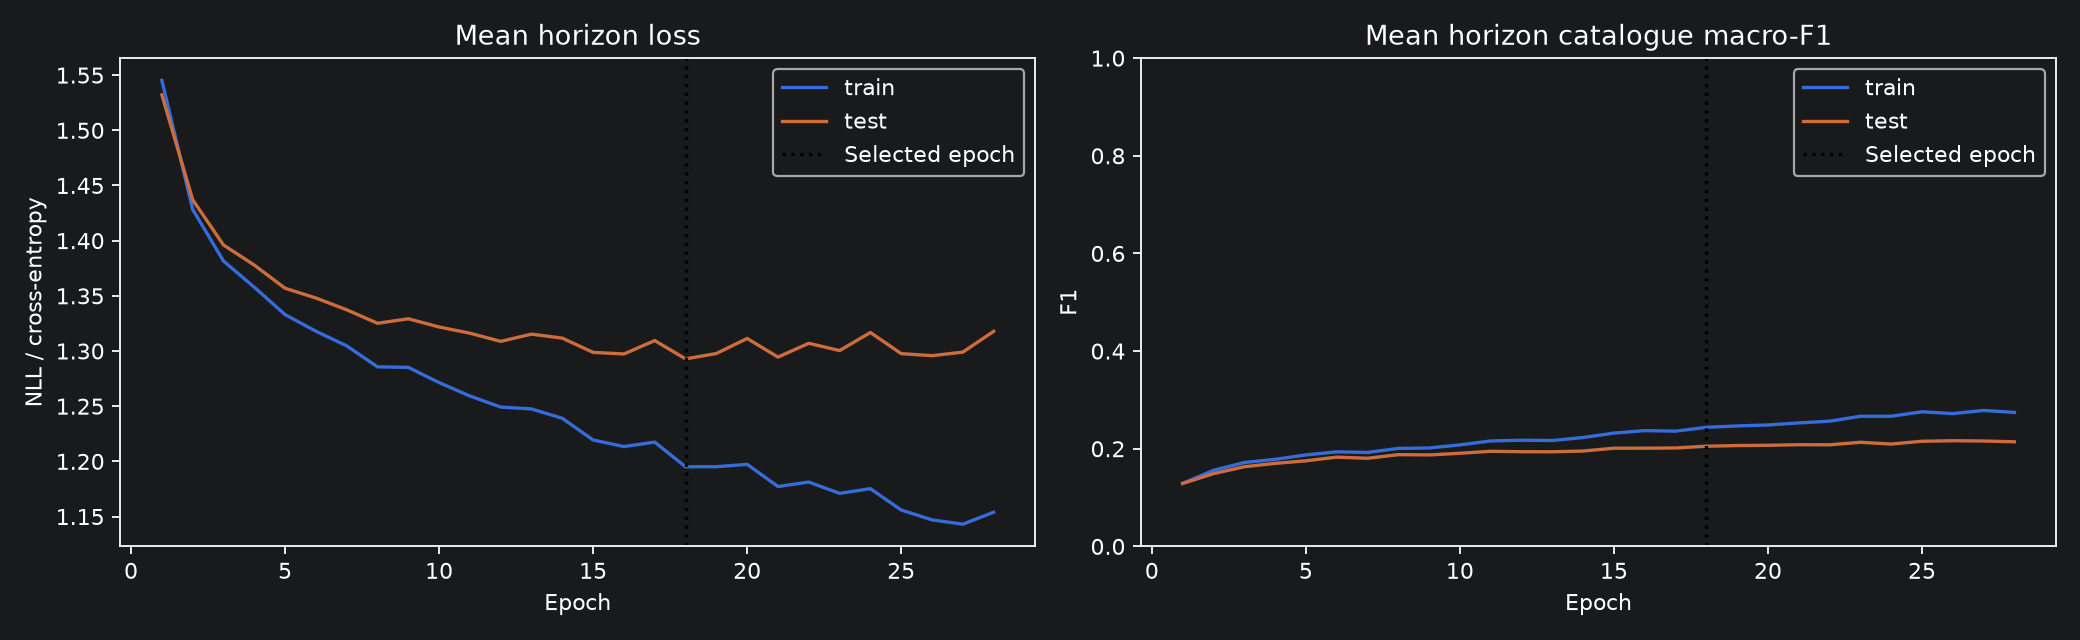

[learning_curves, 0.21s] Done: learning_curves.png
[final_split_comparison, 0.00s] Laying out figure
[final_split_comparison, 0.04s] Rendering PNG
[final_split_comparison, 0.18s] Writing PNG
[final_split_comparison, 0.18s] Displaying saved PNG inline


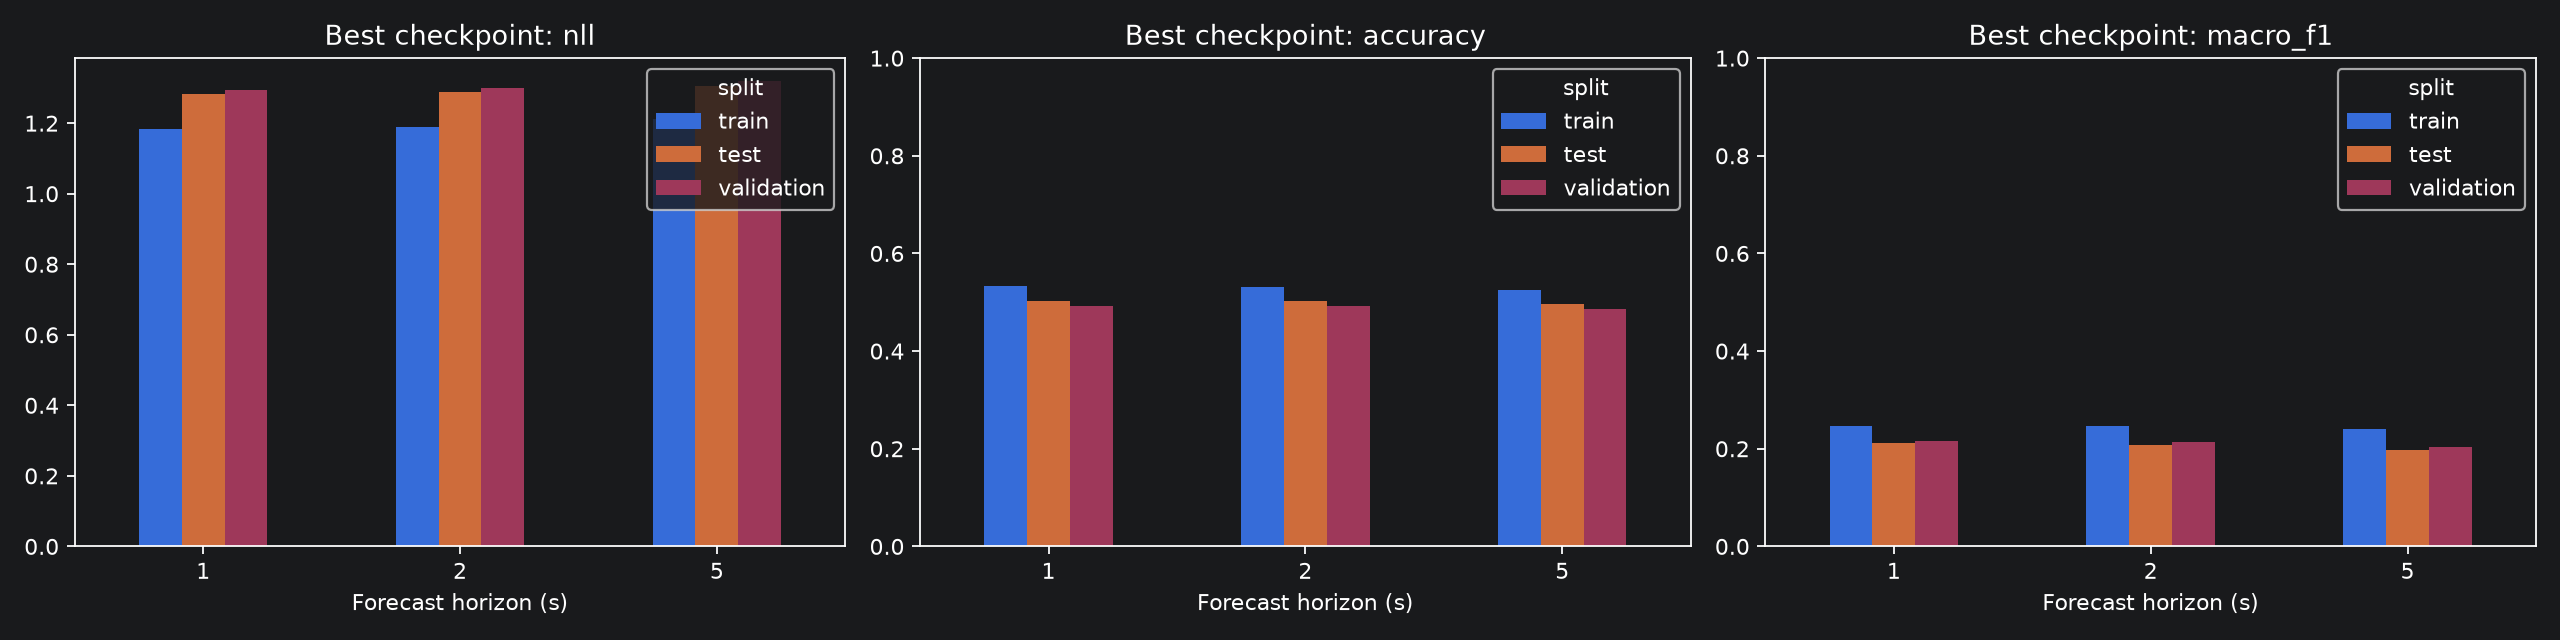

[final_split_comparison, 0.18s] Done: final_split_comparison.png
CPU times: total: 469 ms
Wall time: 595 ms


In [4]:
%%time
DIAGNOSTICS = RUN / "diagnostics"
DIAGNOSTICS.mkdir(exist_ok=True)

# Also select Agg here so rerunning this cell fixes an already-running kernel.
from io import BytesIO
from time import perf_counter
import matplotlib
matplotlib.use("Agg", force=True)
import matplotlib.pyplot as plt
from IPython.display import Image, display

print(f"Diagnostics backend: {matplotlib.get_backend()}; output: {DIAGNOSTICS}", flush=True)

def show_figure(fig, name):
    started = perf_counter()
    def stage(message):
        print(f"[{name}, {perf_counter() - started:.2f}s] {message}", flush=True)

    try:
        stage("Laying out figure")
        # tight_layout fits labels inside the fixed canvas. A second tight-bbox
        # save would render again; inherited savefig.bbox settings are overridden.
        with matplotlib.rc_context({"savefig.bbox": None}):
            fig.tight_layout()
            stage("Rendering PNG")
            with BytesIO() as buffer:
                fig.savefig(buffer, format="png", dpi=160)
                png = buffer.getvalue()
        path = DIAGNOSTICS / f"{name}.png"
        stage("Writing PNG")
        path.write_bytes(png)
        stage("Displaying saved PNG inline")
        display(Image(data=png))  # Reuse the render; plt.show() can block on GUI backends.
        stage(f"Done: {path.name}")
    finally:
        plt.close(fig)  # Release large figures even if saving/display fails.

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for split in ["train", "test"]:
    axes[0].plot(history.epoch, history[f"{split}_nll"], label=split)
    axes[1].plot(history.epoch, history[f"{split}_macro_f1"], label=split)
for ax in axes:
    ax.axvline(best_epoch, color="black", linestyle=":", label="Selected epoch")
    ax.set_xlabel("Epoch")
    ax.legend()
axes[0].set(title="Mean horizon loss", ylabel="NLL / cross-entropy")
axes[1].set(title="Mean horizon catalogue macro-F1", ylabel="F1", ylim=(0, 1))
show_figure(fig, "learning_curves")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, measure in zip(axes, ["nll", "accuracy", "macro_f1"]):
    final_metrics.pivot(index="horizon_s", columns="split", values=measure)[list(SPLITS)].plot(
        kind="bar", ax=ax, rot=0)
    ax.set(title=f"Best checkpoint: {measure}", xlabel="Forecast horizon (s)")
    if measure != "nll": ax.set_ylim(0, 1)
show_figure(fig, "final_split_comparison")

# Plotting uses CPU arrays and does not submit CUDA work.


[per_class_f1_and_support, 0.00s] Laying out figure
[per_class_f1_and_support, 0.11s] Rendering PNG
[per_class_f1_and_support, 0.80s] Writing PNG
[per_class_f1_and_support, 0.80s] Displaying saved PNG inline


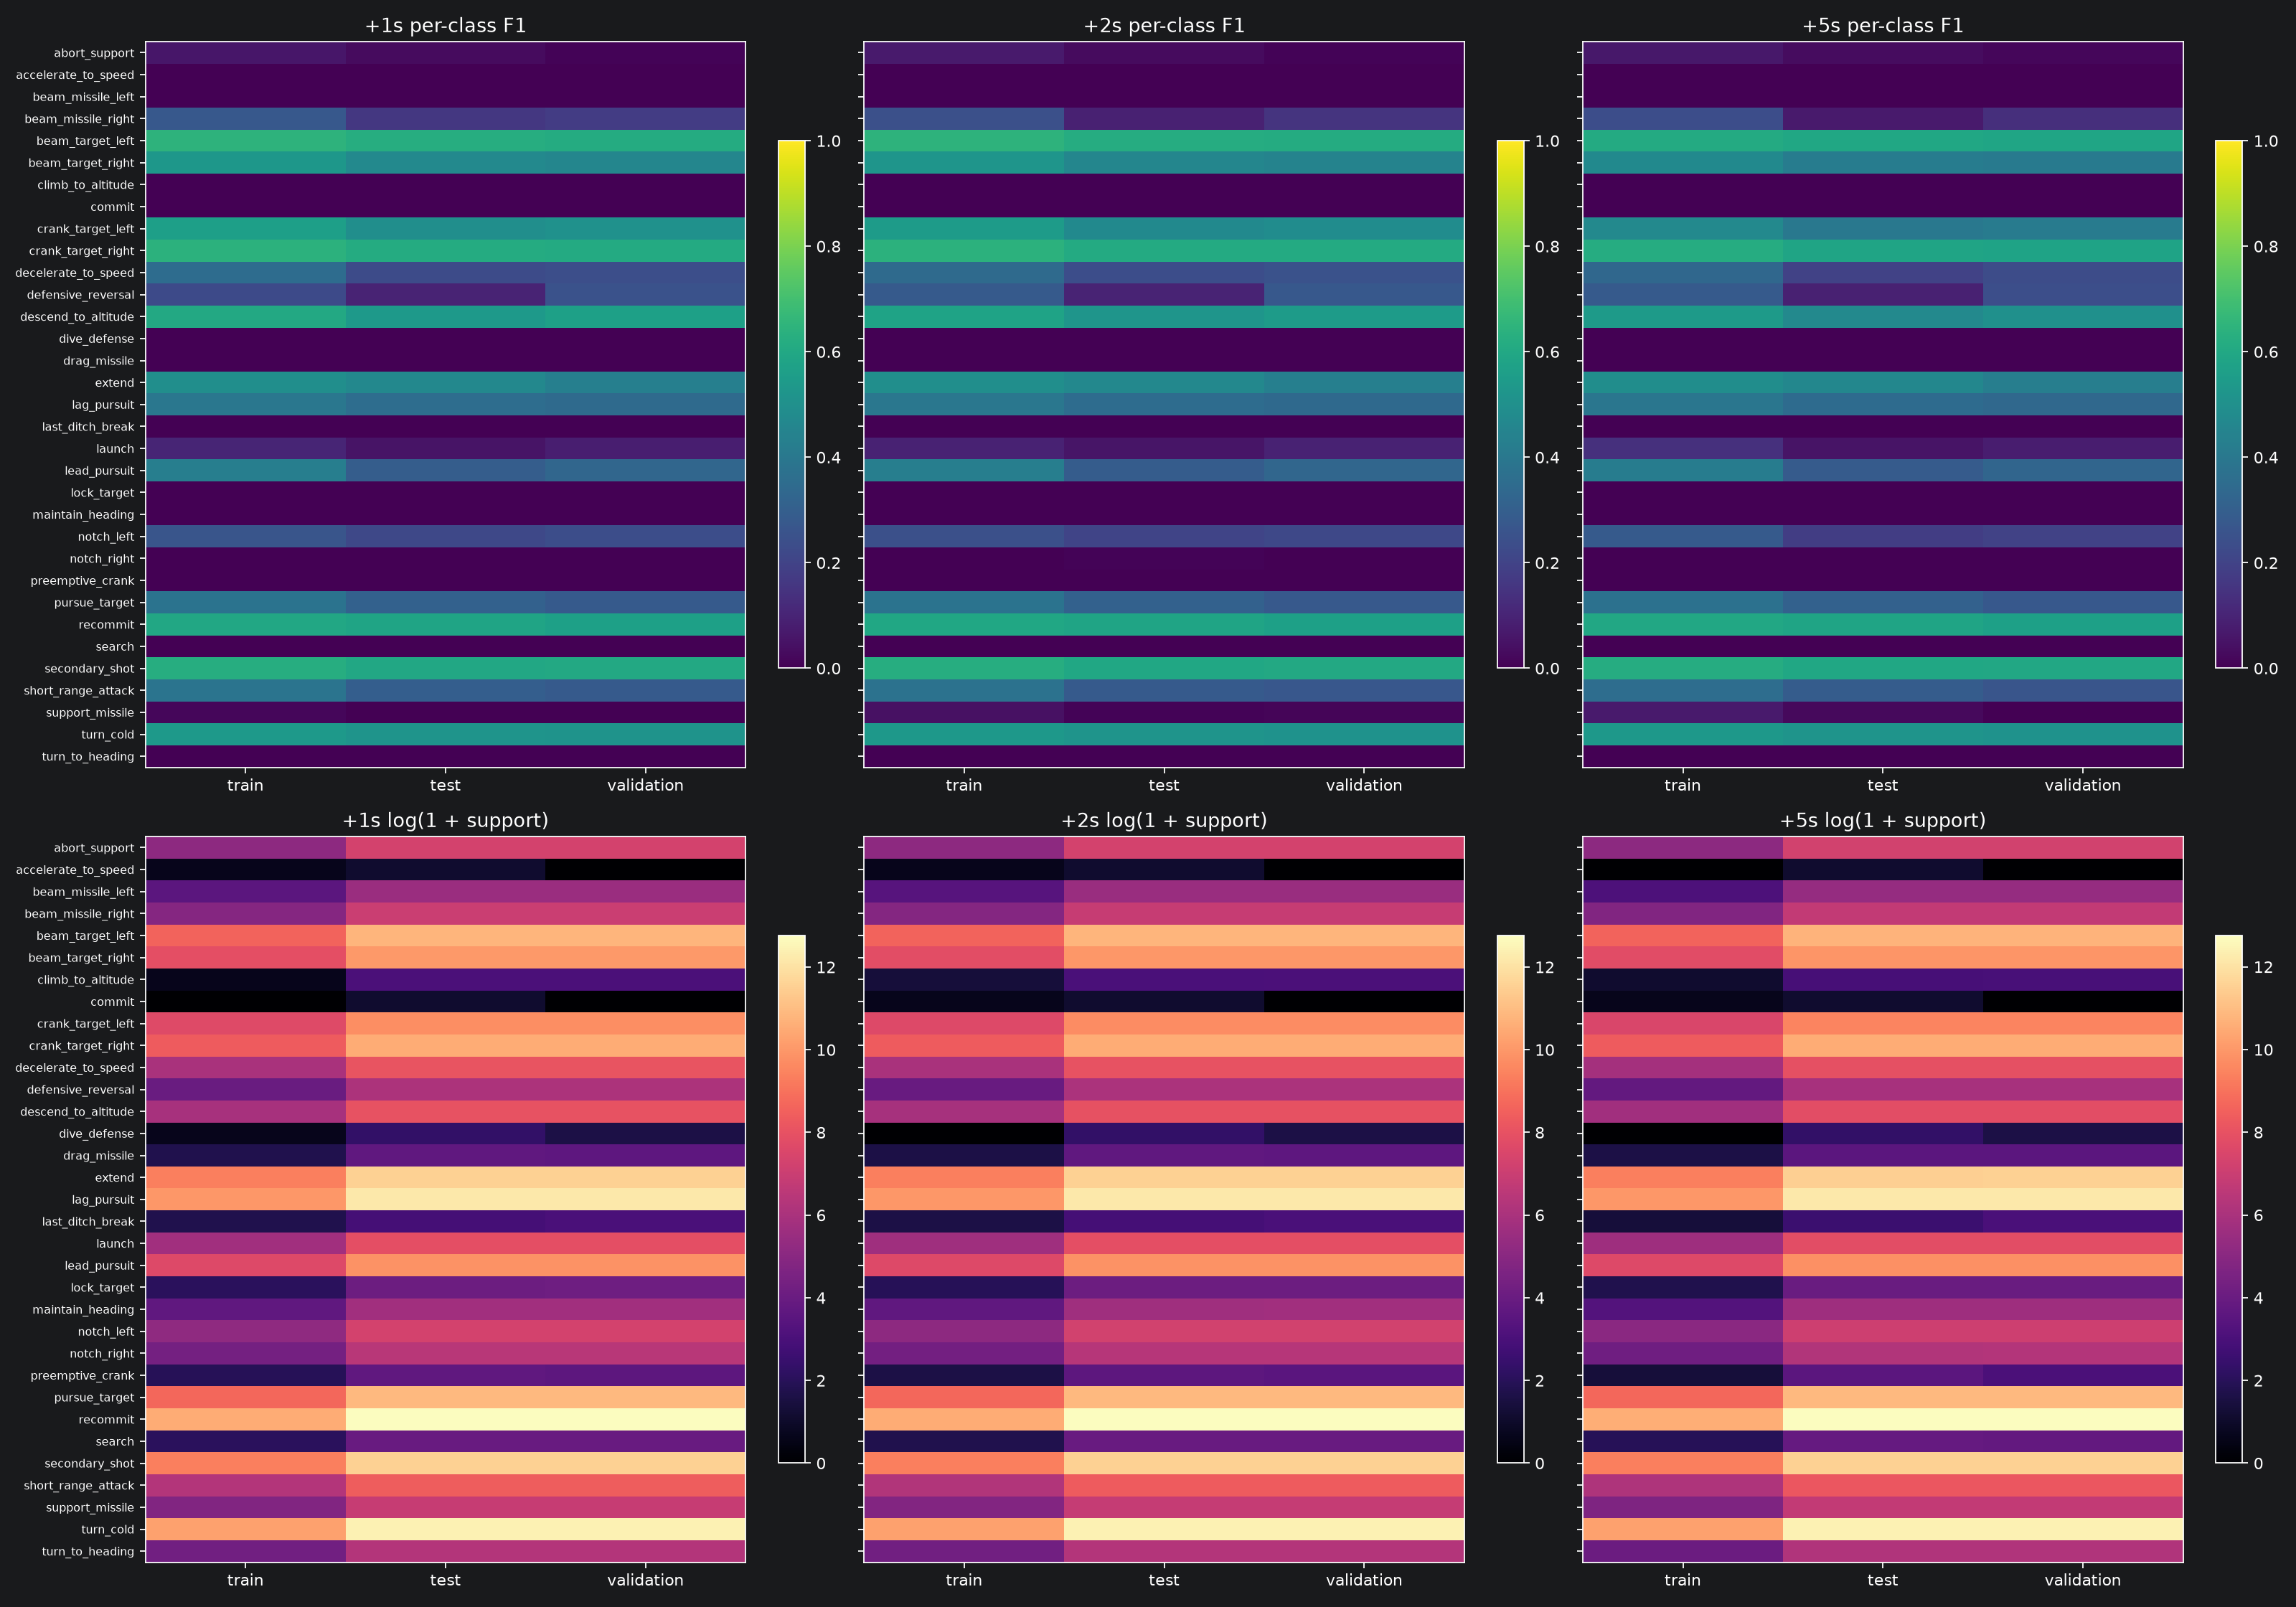

[per_class_f1_and_support, 0.80s] Done: per_class_f1_and_support.png
[confusion_matrices, 0.00s] Laying out figure
[confusion_matrices, 0.22s] Rendering PNG
[confusion_matrices, 2.19s] Writing PNG
[confusion_matrices, 2.19s] Displaying saved PNG inline


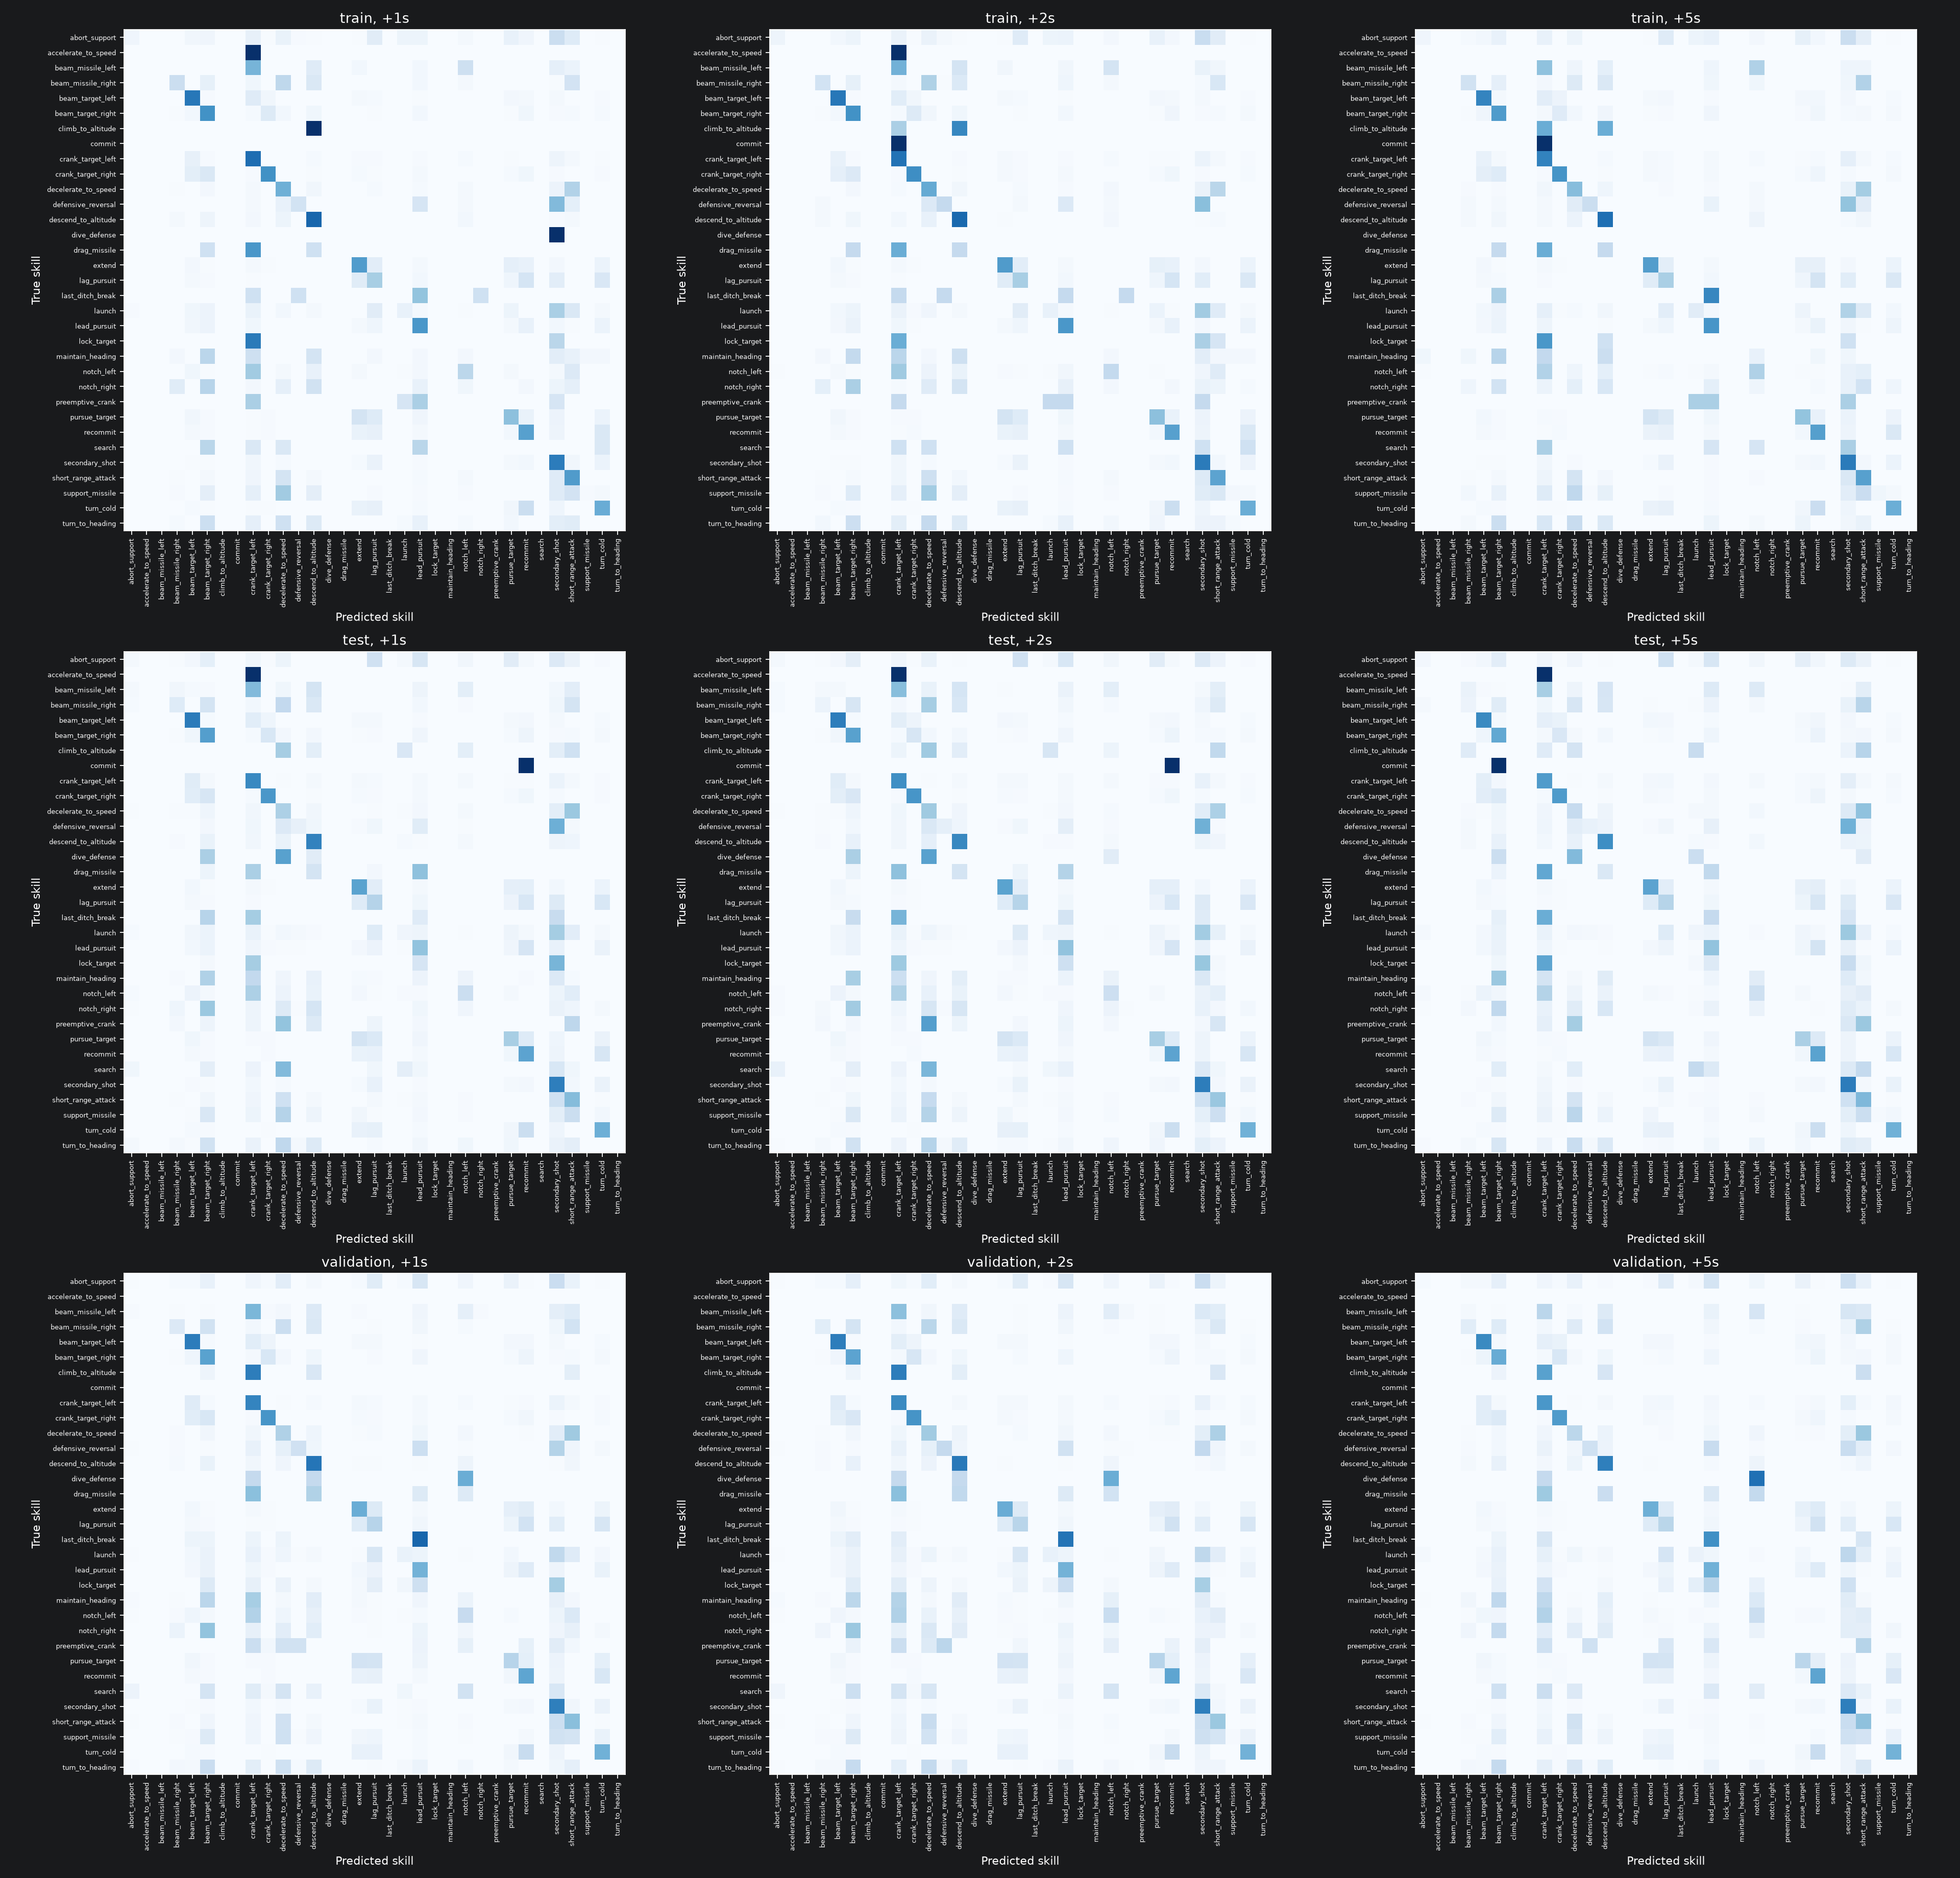

[confusion_matrices, 2.20s] Done: confusion_matrices.png
CPU times: total: 3.5 s
Wall time: 3.64 s


In [5]:
%%time
# F1 and support for all catalogue labels, split by horizon.
fig, axes = plt.subplots(2, 3, figsize=(20, 14), sharey=True)
for h, horizon in enumerate(HORIZONS):
    subset = final_per_class.loc[final_per_class.horizon_s.eq(horizon)]
    f1 = subset.pivot(index="skill", columns="split", values="f1").reindex(
        index=data.classes, columns=SPLITS)
    counts = subset.pivot(index="skill", columns="split", values="support").reindex(
        index=data.classes, columns=SPLITS)
    image = axes[0, h].imshow(f1, vmin=0, vmax=1, aspect="auto", cmap="viridis")
    count_image = axes[1, h].imshow(np.log1p(counts), aspect="auto", cmap="magma")
    for ax in axes[:, h]:
        ax.set_xticks(range(3), SPLITS)
        ax.set_yticks(range(len(data.classes)), data.classes, fontsize=7)
    axes[0, h].set_title(f"+{horizon}s per-class F1")
    axes[1, h].set_title(f"+{horizon}s log(1 + support)")
    fig.colorbar(image, ax=axes[0, h], fraction=.04)
    fig.colorbar(count_image, ax=axes[1, h], fraction=.04)
show_figure(fig, "per_class_f1_and_support")

fig, axes = plt.subplots(3, 3, figsize=(24, 23))
for row, split in enumerate(SPLITS):
    for h, horizon in enumerate(HORIZONS):
        cm = final_results[split]["confusion"][h]
        totals = cm.sum(1, keepdims=True)
        normalized = np.divide(cm, totals, out=np.zeros_like(cm, float), where=totals > 0)
        ax = axes[row, h]
        ax.imshow(normalized, vmin=0, vmax=1, cmap="Blues")
        ax.set_xticks(range(len(data.classes)), data.classes, rotation=90, fontsize=6)
        ax.set_yticks(range(len(data.classes)), data.classes, fontsize=6)
        ax.set(title=f"{split}, +{horizon}s", xlabel="Predicted skill", ylabel="True skill")
show_figure(fig, "confusion_matrices")

# Plotting uses CPU arrays and does not submit CUDA work.


[reliability, 0.00s] Laying out figure
[reliability, 0.06s] Rendering PNG
[reliability, 0.23s] Writing PNG
[reliability, 0.23s] Displaying saved PNG inline


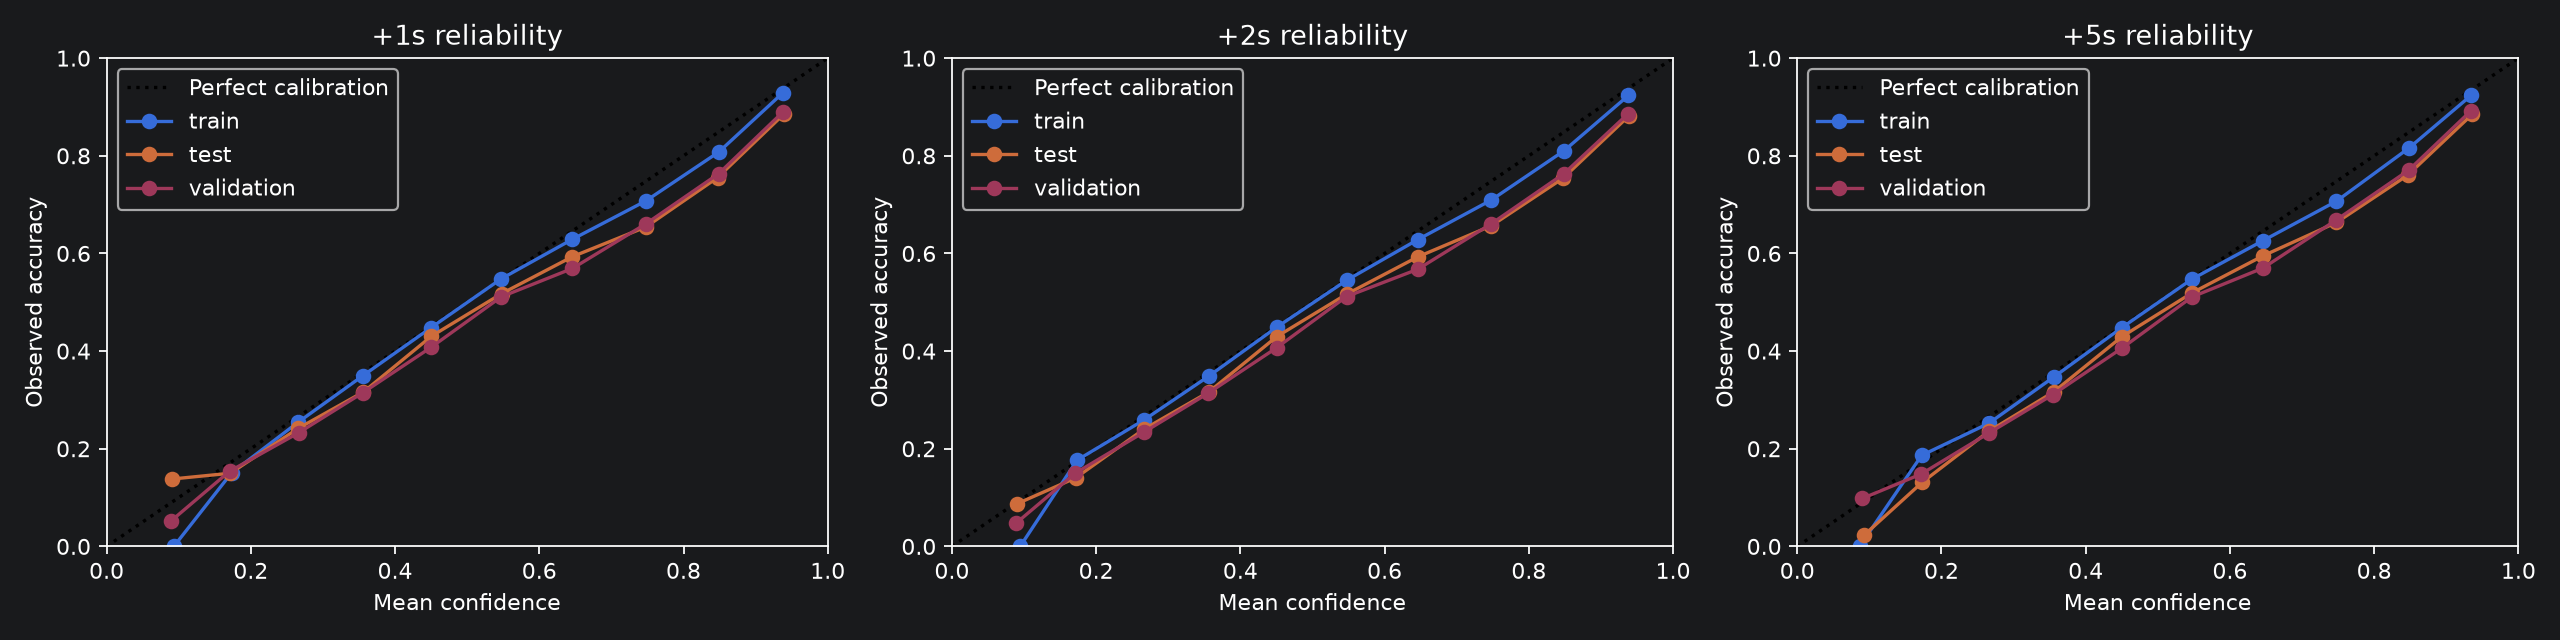

[reliability, 0.24s] Done: reliability.png


class_nll                          f1          \
split                              test    train validation    test   train   
horizon_s skill                                                               
1         abort_support          4.0449   3.1162     3.8906  0.0292  0.0596   
          accelerate_to_speed    9.4066   8.4165        NaN  0.0000  0.0000   
          beam_missile_left      4.5918   4.5070     4.7746  0.0000  0.0000   
          beam_missile_right     2.7043   2.2466     2.5745  0.1641  0.2762   
          beam_target_left       0.9015   0.8384     0.9006  0.6245  0.6469   
          beam_target_right      1.3990   1.1959     1.4295  0.4708  0.5291   
          climb_to_altitude     10.0894  10.5538     9.2798  0.0000  0.0000   
          commit                 8.6077      NaN        NaN  0.0000  0.0000   
          crank_target_left      1.1848   0.8506     1.1089  0.4931  0.5643   
          crank_target_right     1.1155   1.0126     1.0941  0.6142  0.6433   
          decelerate_to_speed    1.7272   1.4324     1.9144  0.2299  0.3518   
          defensive_reversal     3.6015   2.4692     3.2269  0.0985  0.2247   
          descend_to_altitude    1.3436   0.8731     1.0542  0.5409  0.6034   
          dive_defense          10.3885   8.1994     7.8400  0.0000  0.0000   
          drag_missile           7.3278   5.7041     6.0812  0.0000  0.0000   
          extend                 1.4182   1.2939     1.5128  0.4664  0.4947   
          lag_pursuit            1.5792   1.4557     1.6026  0.3559  0.3979   
          last_ditch_break       8.5685   4.9695     8.6067  0.0000  0.0000   
          launch                 3.1941   2.8471     3.3446  0.0532  0.1040   
          lead_pursuit           2.0811   1.3251     1.8254  0.2937  0.4284   
          lock_target            6.4587   6.0849     7.1492  0.0000  0.0000   
          maintain_heading       4.5185   3.9472     4.0343  0.0000  0.0000   
          notch_left             2.5244   2.0855     2.4475  0.2165  0.2629   
          notch_right            3.9476   3.6329     4.1177  0.0000  0.0000   
          preemptive_crank       8.7653   6.3500     7.6945  0.0000  0.0000   
          pursue_target          1.7923   1.5009     1.8864  0.3113  0.3825   
          recommit               1.1524   1.1193     1.1610  0.5824  0.5977   
          search                 6.5947   6.0227     7.0114  0.0000  0.0000   
          secondary_shot         0.9897   0.9426     0.9968  0.5979  0.6216   
          short_range_attack     1.7497   1.2577     1.7137  0.2981  0.3832   
          support_missile        3.9006   3.1206     4.5384  0.0000  0.0164   
          turn_cold              1.1254   1.0840     1.1134  0.5184  0.5354   
          turn_to_heading        4.4156   4.2354     4.2202  0.0000  0.0000   
2         abort_support          4.0190   3.0446     3.8935  0.0297  0.0741   
          accelerate_to_speed    8.9695   8.0394        NaN  0.0000  0.0000   
          beam_missile_left      4.8029   4.4454     4.8507  0.0000  0.0000   
          beam_missile_right     2.8405   2.3931     2.6789  0.0910  0.2424   
          beam_target_left       0.9236   0.8511     0.9187  0.6196  0.6468   
          beam_target_right      1.4152   1.2112     1.4457  0.4579  0.5227   
          climb_to_altitude      8.7741   7.2788     7.8041  0.0000  0.0000   
          commit                 7.9388   8.2901        NaN  0.0000  0.0000   
          crank_target_left      1.2574   0.9126     1.1811  0.4731  0.5505   
          crank_target_right     1.1291   1.0207     1.1091  0.6121  0.6440   
          decelerate_to_speed    1.7046   1.4046     1.8941  0.2359  0.3449   
          defensive_reversal     3.5645   2.4202     3.1284  0.1000  0.2826   
          descend_to_altitude    1.4523   0.9059     1.1446  0.5211  0.5818   
          dive_defense          10.7851      NaN     9.7259  0.0000  0.0000   
          drag_missile           7.4965   5.9549     6.3589  0.0000  0.0000   
 

Saved metrics, predictions, checkpoints and PNG diagnostics to: C:\Users\theon\Trajectory_Classification\artifacts\nn_duel_balanced_forecasting\runs\nn-duel-balanced-s42_20261109T145721621078Z
MLflow run: 2098c87838774a24b6550a5028422a77 (nn-duel-balanced-skill-forecasting)
MLflow run ID: 2098c87838774a24b6550a5028422a77
CPU times: total: 1.55 s
Wall time: 1.57 s


In [6]:
%%time
# Probability calibration: each point averages one confidence bin.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for h, horizon in enumerate(HORIZONS):
    axes[h].plot([0, 1], [0, 1], "k:", label="Perfect calibration")
    for split in SPLITS:
        result = final_results[split]
        valid = result["targets"][:, h] >= 0
        p = result["probabilities"][valid, h]
        y = result["targets"][valid, h]
        confidence, correct = p.max(-1), p.argmax(-1) == y
        bins = np.minimum((confidence * 10).astype(int), 9)
        points = [(confidence[bins == b].mean(), correct[bins == b].mean())
                  for b in range(10) if (bins == b).any()]
        axes[h].plot(*np.asarray(points).T, marker="o", label=split)
    axes[h].set(title=f"+{horizon}s reliability", xlabel="Mean confidence",
                ylabel="Observed accuracy", xlim=(0, 1), ylim=(0, 1))
    axes[h].legend()
show_figure(fig, "reliability")

with pd.option_context("display.max_rows", None):
    display(final_per_class.pivot(index=["horizon_s", "skill"], columns="split",
                                  values=["class_nll", "f1", "support"]).round(4))
print("Saved metrics, predictions, checkpoints and PNG diagnostics to:", RUN)
if MLFLOW_ENABLED:
    log_run_artifacts(RUN)  # Attach final figures and baseline tables to the same run.
if (RUN / "mlflow.json").exists():
    print("MLflow run ID:", read_json(RUN / "mlflow.json")["run_id"])

# Plotting uses CPU arrays and does not submit CUDA work.


The saved `best.pt` contains the expanded input projection, class vocabulary, feature
ordering, three horizon heads, dataset digest and model configuration. For inference,
recreate the **same causal 51-frame inputs**, including the observing aircraft's own
current skill and training-only scaling. Load with
`PairedTransformer(num_classes=len(checkpoint["classes"]), **checkpoint["model_config"])`
and `model.load_state_dict(checkpoint["model_state"])`. Never substitute the opponent's
current skill for the observer's own skill. Source code and provenance accompany every run.
